<a href="https://colab.research.google.com/github/Cmay487/Premier_League_Match_Prediction/blob/UpdatedWorkbook_0308/ApplyingProbabilityToFootball.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📄 Notes on the Data


---

## ⚽ Key to Results Data

| Column | Description |
|--------|-------------|
| **Div** | League Division |
| **Date** | Match Date (dd/mm/yy) |
| **Time** | Time of match kick-off |
| **HomeTeam** | Home Team |
| **AwayTeam** | Away Team |
| **FTHG / HG** | Full Time Home Team Goals |
| **FTAG / AG** | Full Time Away Team Goals |
| **FTR / Res** | Full Time Result (`H` = Home Win, `D` = Draw, `A` = Away Win) |
| **HTHG** | Half Time Home Team Goals |
| **HTAG** | Half Time Away Team Goals |
| **HTR** | Half Time Result (`H` = Home Win, `D` = Draw, `A` = Away Win) |

---

## 📊 Match Statistics (where available)

| Column | Description |
|--------|-------------|
| **Attendance** | Crowd Attendance |
| **Referee** | Match Referee |
| **HS / AS** | Home / Away Shots |
| **HST / AST** | Home / Away Shots on Target |
| **HHW / AHW** | Home / Away Hit Woodwork |
| **HC / AC** | Home / Away Corners |
| **HF / AF** | Home / Away Fouls Committed |
| **HFKC / AFKC** | Home / Away Free Kicks Conceded |
| **HO / AO** | Home / Away Offsides |
| **HY / AY** | Home / Away Yellow Cards |
| **HR / AR** | Home / Away Red Cards |
| **HBP / ABP** | Home / Away Bookings Points (10 = yellow, 25 = red) |

> **Note 1:** Free Kicks Conceded includes fouls, offsides, and any other offence committed, and will always be equal to or higher than the number of fouls.  
> **Note 2:** English and Scottish yellow cards do not include the initial yellow when a second is shown that becomes a red (European games include it).

---

## 💰 Betting Odds Data (Pre-Closing Odds)

### Bookmaker Codes

| Code | Description |
|------|-------------|
| **B365H / B365D / B365A** | Bet365 home/draw/away odds |


# 📄 Section Notes
---



# Libraries

In [ ]:
import warnings
warnings.filterwarnings('ignore')
# funcs
from utils.get_data import extractWebData
from utils.probability import ProbabilityModelling
from utils.plotting import *
from utils.analysis import *
from utils.feature_engineering import *

# standard libraries for EDA
import scipy.stats as stats
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import (
    binom, beta, poisson, expon, geom, nbinom,
    chi2_contingency
)

# set sns theme
sns.set_theme(style="whitegrid", palette="pastel")



<class 'pandas.DataFrame'>
Index: 2760 entries, 0 to 379
Data columns (total 62 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   League Division     2760 non-null   str    
 1   Date                2760 non-null   str    
 2   Time                2760 non-null   str    
 3   HomeTeam            2760 non-null   str    
 4   AwayTeam            2760 non-null   str    
 5   FT_HomeGoals        2760 non-null   int64  
 6   FT_AwayGoals        2760 non-null   int64  
 7   FT_Result           2760 non-null   str    
 8   HT_HomeGoals        2760 non-null   int64  
 9   HT_AwayGoals        2760 non-null   int64  
 10  HT_Result           2760 non-null   str    
 11  Match Referee       2760 non-null   str    
 12  HomeShots           2760 non-null   int64  
 13  AwayShots           2760 non-null   int64  
 14  HomeShotsonTarget   2760 non-null   int64  
 15  AwayShotsonTarget   2760 non-null   int64  
 16  HomeFoulsCommitted  276

# Web Scraping the data

In [ ]:

# call class as object
scaper = extractWebData('https://www.football-data.co.uk/englandm.php', 8)
df = scaper.run_web_scrape()

# save data in its raw form
df.to_csv('data/raw_data.csv',index=False)

df.info()

<class 'pandas.DataFrame'>
Index: 2760 entries, 0 to 379
Data columns (total 62 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   League Division     2760 non-null   str    
 1   Date                2760 non-null   str    
 2   Time                2760 non-null   str    
 3   HomeTeam            2760 non-null   str    
 4   AwayTeam            2760 non-null   str    
 5   FT_HomeGoals        2760 non-null   int64  
 6   FT_AwayGoals        2760 non-null   int64  
 7   FT_Result           2760 non-null   str    
 8   HT_HomeGoals        2760 non-null   int64  
 9   HT_AwayGoals        2760 non-null   int64  
 10  HT_Result           2760 non-null   str    
 11  Match Referee       2760 non-null   str    
 12  HomeShots           2760 non-null   int64  
 13  AwayShots           2760 non-null   int64  
 14  HomeShotsonTarget   2760 non-null   int64  
 15  AwayShotsonTarget   2760 non-null   int64  
 16  HomeFoulsCommitted  276

# Data Cleaning

## NaN Values

In [ ]:
 # count the number of Nan - It should be 1
df.isna().sum().sort_values(ascending=False)

League Division    0
Date               0
Time               0
HomeTeam           0
AwayTeam           0
                  ..
AvgC<2.5           0
AHCh               0
AvgCAHH            0
AvgCAHA            0
Season             0
Length: 62, dtype: int64

## Outliers

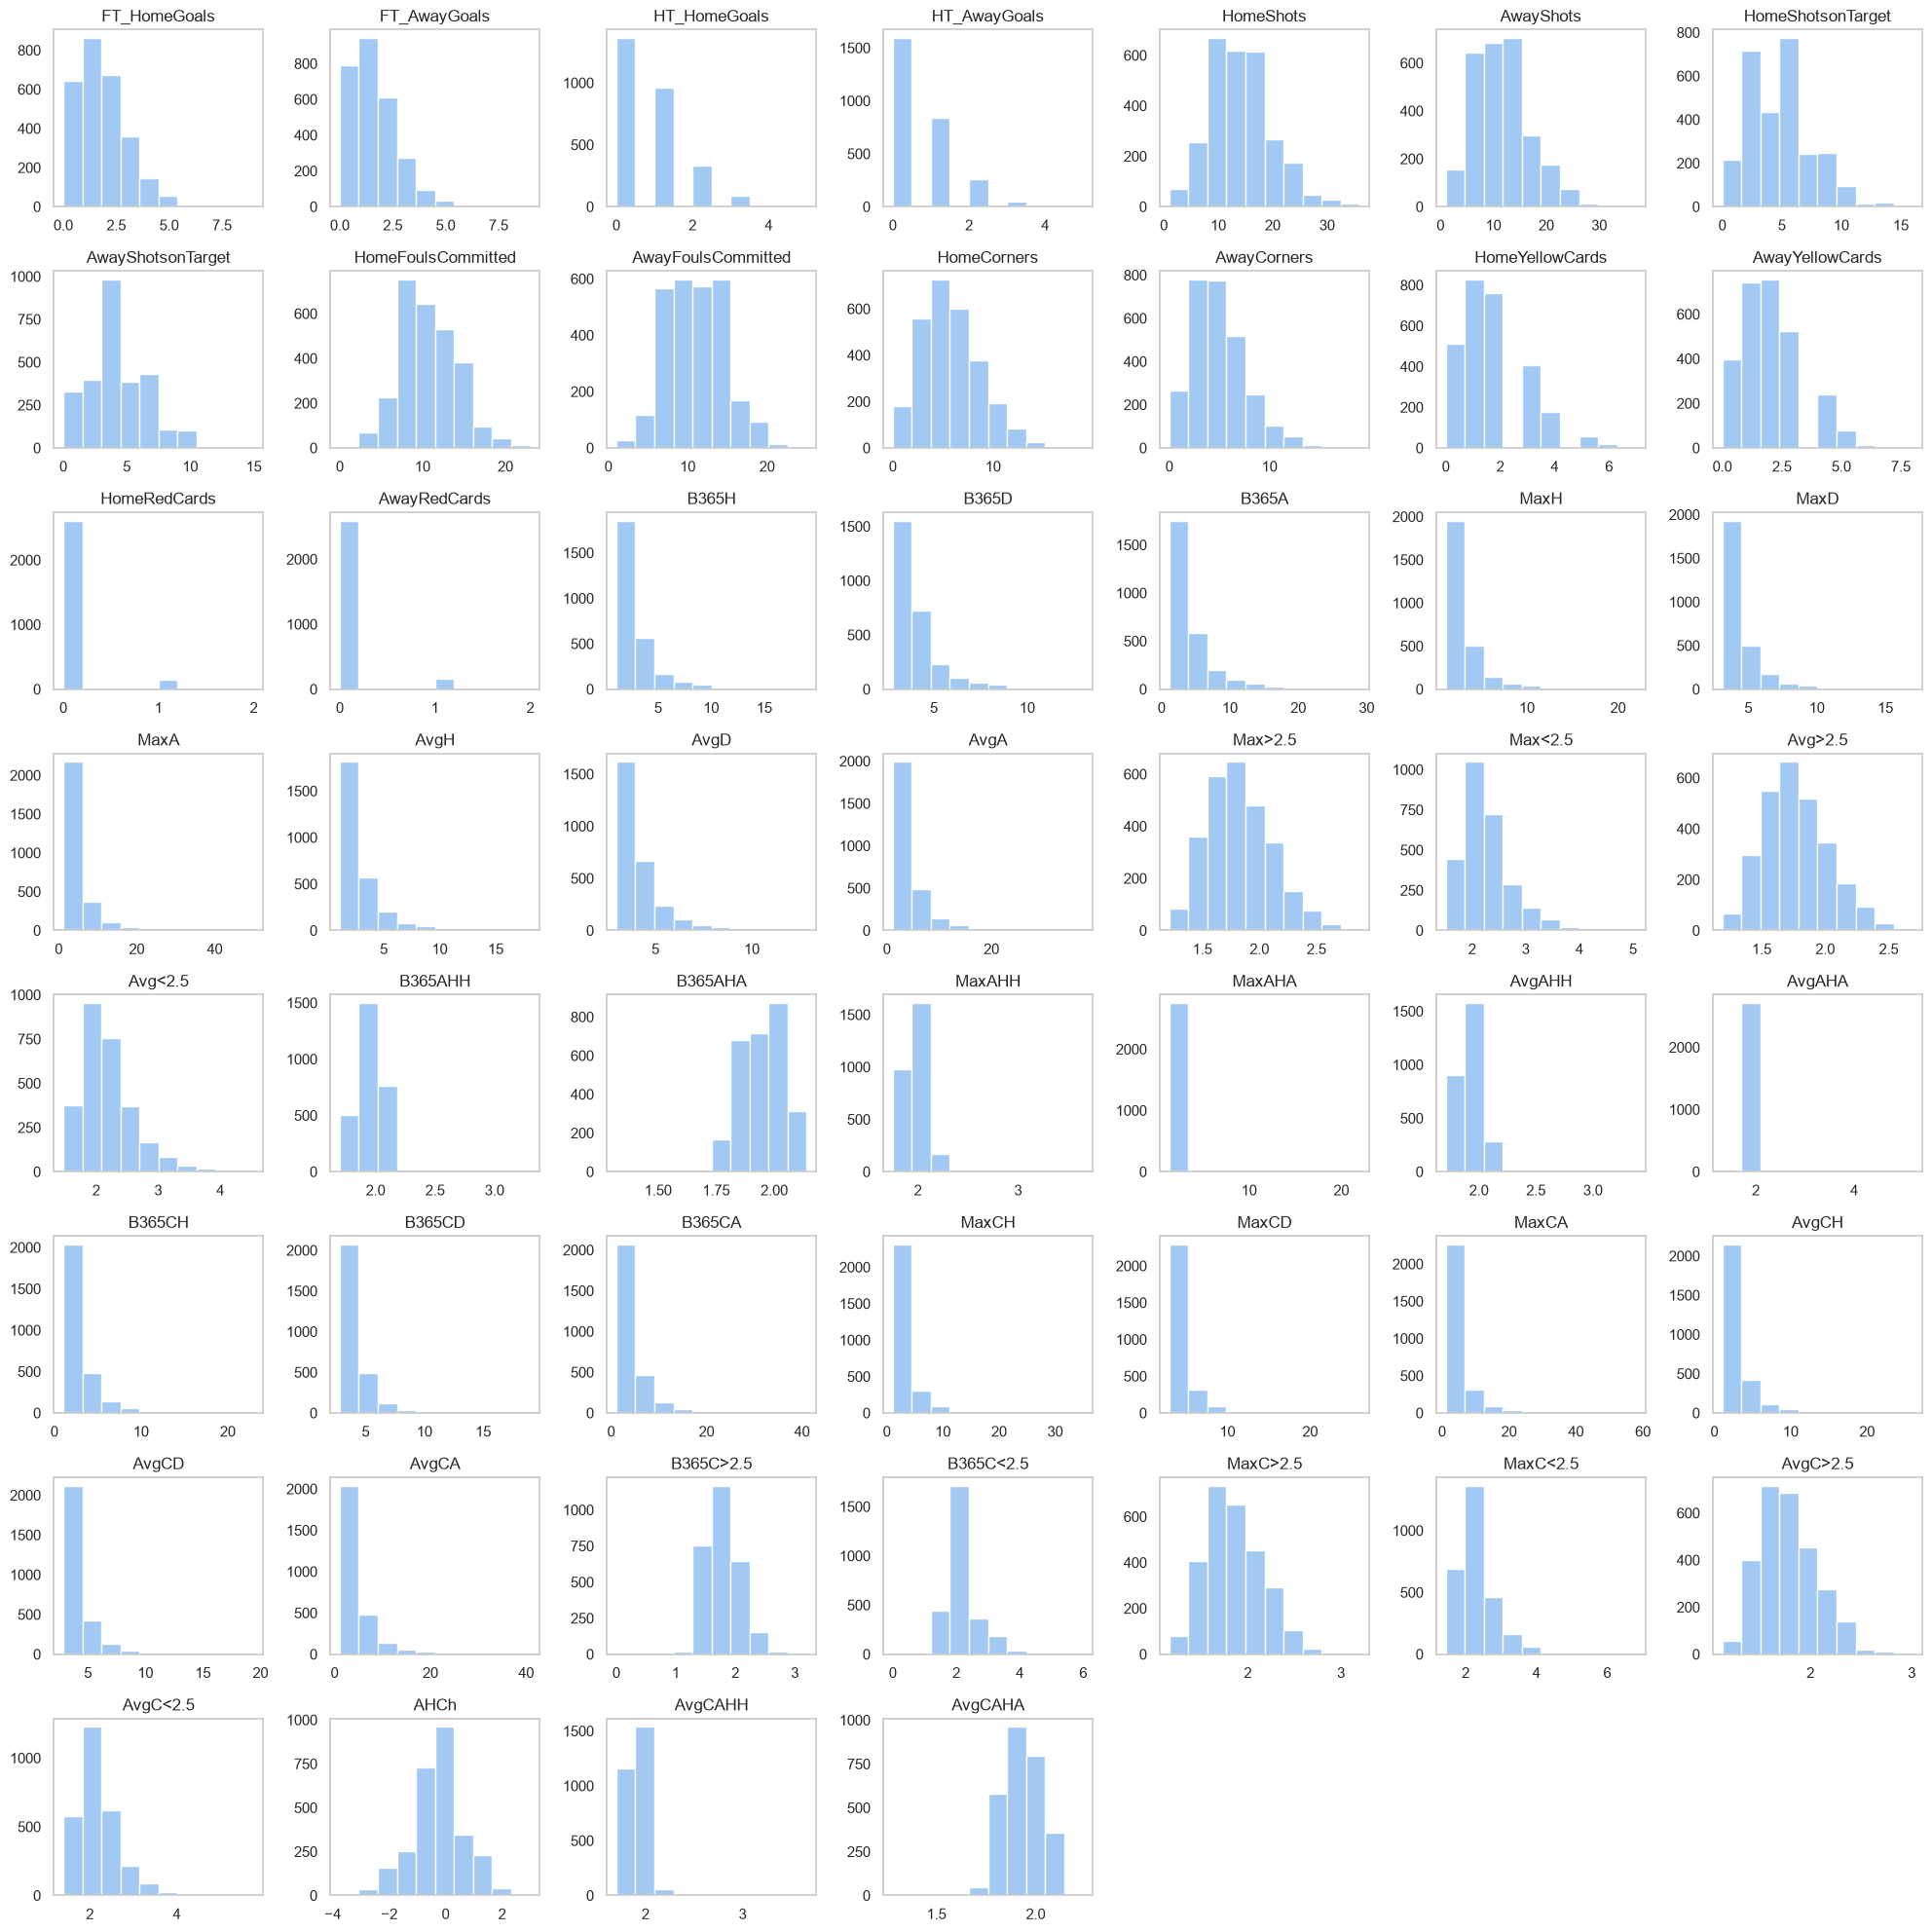

In [ ]:
# visualise the distribution to see any outliers
df.hist(figsize=(20,20),grid=False);

plt.tight_layout()

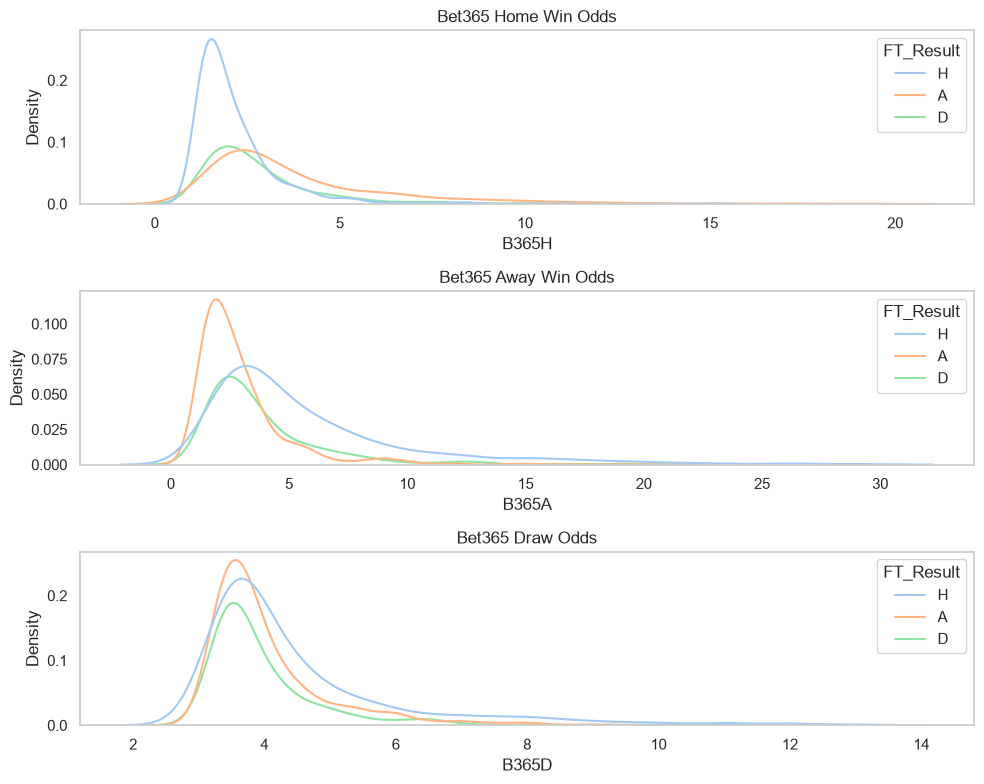

In [ ]:
# The Bet365 features look to have extreme values.
# Lets investigate why this and validate if they are true outliers

bet365 = df[['B365H','B365D','B365A','FT_Result']].copy()

fig,axes = plt.subplots(3,1,figsize=(10,8))
sns.kdeplot(data=bet365,x='B365H',hue='FT_Result',ax=axes[0]);
sns.kdeplot(data=bet365,x='B365A',hue='FT_Result',ax=axes[1]);
sns.kdeplot(data=bet365,x='B365D',hue='FT_Result',ax=axes[2]);

axes[0].set_title('Bet365 Home Win Odds');
axes[1].set_title('Bet365 Away Win Odds');
axes[2].set_title('Bet365 Draw Odds');

# remove grid 
for ax in axes:
    ax.grid(False)
    
plt.tight_layout()

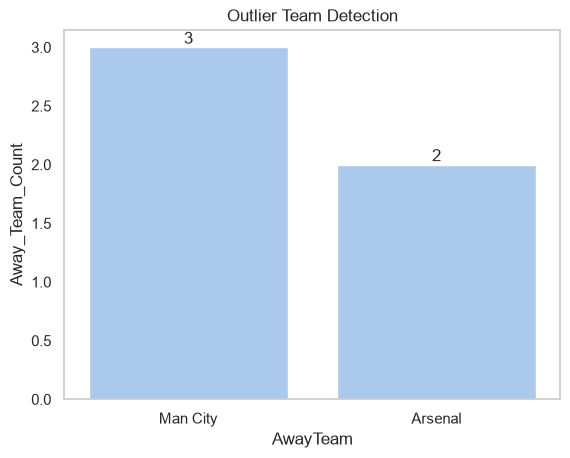

In [ ]:
# filter out the extreme home win odds to see what those games were
outliers = (df['B365H'] > 15)

agg_df = (df[['HomeTeam','AwayTeam']]
            .loc[outliers]
            .groupby('AwayTeam')
            .agg(Away_Team_Count=('HomeTeam','count'))
            .reset_index()
            .sort_values('Away_Team_Count',ascending=False)
            )

ax = sns.barplot(data=agg_df,x='AwayTeam',y='Away_Team_Count');

for container in ax.containers:
    ax.bar_label(container)

plt.title('Outlier Team Detection')
plt.grid(False)
plt.show()

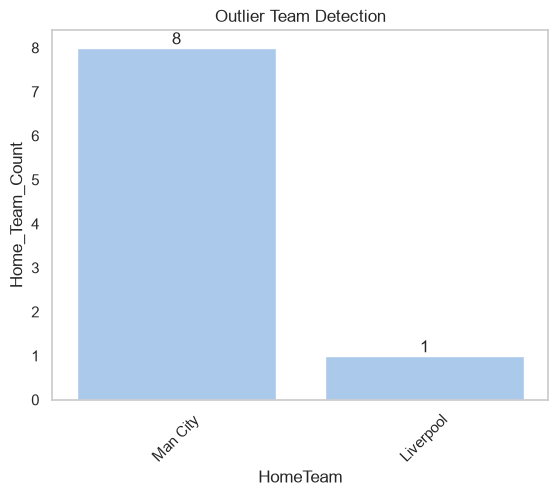

In [ ]:
# filter out the extreme home win odds to see what those games were
outliers = (df['B365A'] > 25)

agg_df = (df[['HomeTeam','AwayTeam']]
            .loc[outliers]
            .groupby('HomeTeam')
            .agg(Home_Team_Count=('HomeTeam','count'))
            .reset_index()
            .sort_values('Home_Team_Count',ascending=False)
            )

ax = sns.barplot(data=agg_df,x='HomeTeam',y='Home_Team_Count');

for container in ax.containers:
    ax.bar_label(container)

for item in ax.get_xticklabels():
    item.set_rotation(45)

plt.title('Outlier Team Detection')
plt.grid(False)
plt.show()

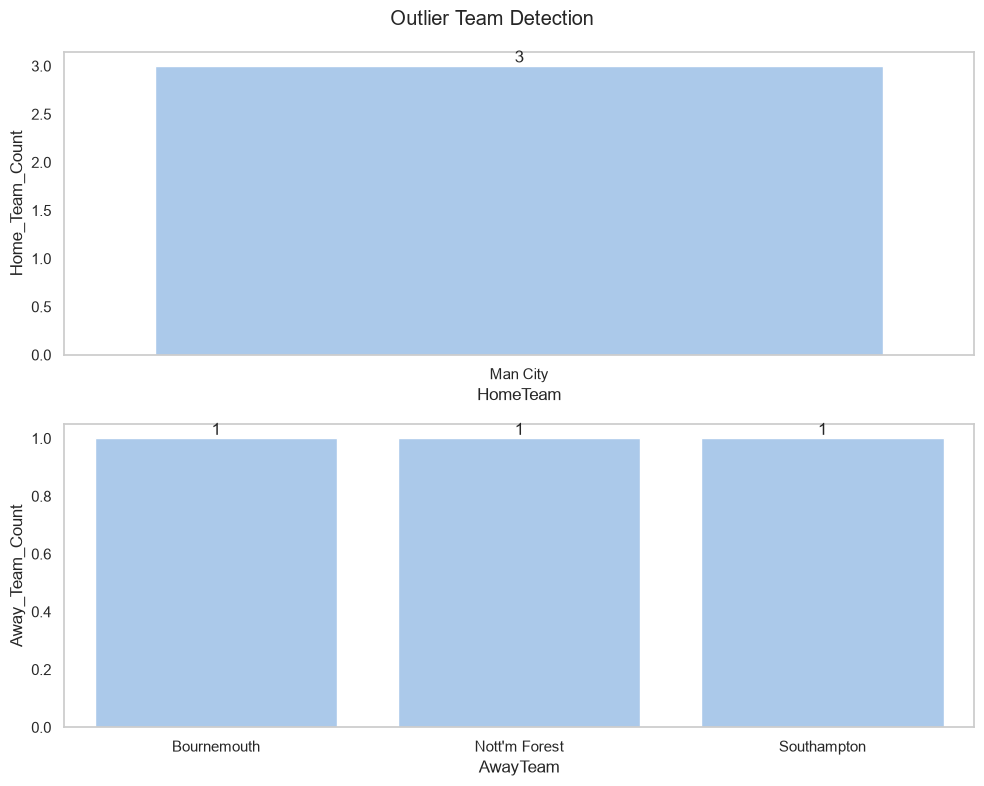

In [ ]:
# filter out the extreme home win odds to see what those games were
outliers = (df['B365D'] > 12)

agg_df = (df[['HomeTeam','AwayTeam']]
            .loc[outliers]
            .groupby('HomeTeam')
            .agg(Home_Team_Count=('HomeTeam','count'))
            .reset_index()
            .sort_values('Home_Team_Count',ascending=False)
            )

agg_dfb = (df[['HomeTeam','AwayTeam']]
            .loc[outliers]
            .groupby('AwayTeam')
            .agg(Away_Team_Count=('HomeTeam','count'))
            .reset_index()
            .sort_values('Away_Team_Count',ascending=False)
            )

fig,axes = plt.subplots(2,1,figsize=(10,8))

ax = sns.barplot(data=agg_df,x='HomeTeam',y='Home_Team_Count',ax=axes[0]);
ax1 = sns.barplot(data=agg_dfb,x='AwayTeam',y='Away_Team_Count',ax=axes[1]);

bars = [ax,ax1]

for bar in bars:
  for container in bar.containers:
      bar.bar_label(container)


plt.suptitle('Outlier Team Detection')
for ax in axes:
   ax.grid(False)
plt.tight_layout()
plt.show()

**Observations**

Based on the observation in the above analysis, it appears that Bet365 favours higher ranked teams (teams that typically place in the top 4/5 in the league) over lower ranked teams. Therefore, these outliers are true datapoints and will remain in the dataset.

## Data Consistency

In [ ]:
df.info()

<class 'pandas.DataFrame'>
Index: 2760 entries, 0 to 379
Data columns (total 62 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   League Division     2760 non-null   str    
 1   Date                2760 non-null   str    
 2   Time                2760 non-null   str    
 3   HomeTeam            2760 non-null   str    
 4   AwayTeam            2760 non-null   str    
 5   FT_HomeGoals        2760 non-null   int64  
 6   FT_AwayGoals        2760 non-null   int64  
 7   FT_Result           2760 non-null   str    
 8   HT_HomeGoals        2760 non-null   int64  
 9   HT_AwayGoals        2760 non-null   int64  
 10  HT_Result           2760 non-null   str    
 11  Match Referee       2760 non-null   str    
 12  HomeShots           2760 non-null   int64  
 13  AwayShots           2760 non-null   int64  
 14  HomeShotsonTarget   2760 non-null   int64  
 15  AwayShotsonTarget   2760 non-null   int64  
 16  HomeFoulsCommitted  276

In [ ]:
# Drop league division as this analysis focuses on Premier League
df.drop(columns='League Division',inplace=True)

In [ ]:
df.info()

<class 'pandas.DataFrame'>
Index: 2760 entries, 0 to 379
Data columns (total 61 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                2760 non-null   str    
 1   Time                2760 non-null   str    
 2   HomeTeam            2760 non-null   str    
 3   AwayTeam            2760 non-null   str    
 4   FT_HomeGoals        2760 non-null   int64  
 5   FT_AwayGoals        2760 non-null   int64  
 6   FT_Result           2760 non-null   str    
 7   HT_HomeGoals        2760 non-null   int64  
 8   HT_AwayGoals        2760 non-null   int64  
 9   HT_Result           2760 non-null   str    
 10  Match Referee       2760 non-null   str    
 11  HomeShots           2760 non-null   int64  
 12  AwayShots           2760 non-null   int64  
 13  HomeShotsonTarget   2760 non-null   int64  
 14  AwayShotsonTarget   2760 non-null   int64  
 15  HomeFoulsCommitted  2760 non-null   int64  
 16  AwayFoulsCommitted  276

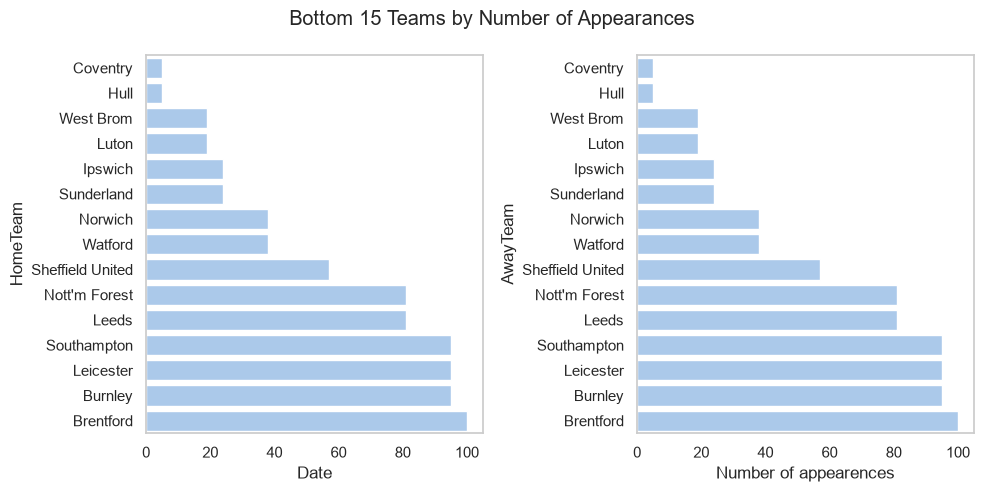

In [ ]:
# Focus on the bottom 15 teams as these will be where inconsistent data entries lie.

# agg the data
hteams = (df.groupby('HomeTeam')['Date']
            .count()
            .reset_index()
            .sort_values(ascending=True,by='Date')
)
ateams = (df.groupby('AwayTeam')['Date']
            .count()
            .reset_index()
            .sort_values(ascending=True,by='Date')
)

# visualise
fig,axes = plt.subplots(1,2,figsize=(10,5))
sns.barplot(data=hteams.head(15),x='Date',y='HomeTeam',ax=axes[0]);
sns.barplot(data=ateams.head(15),x='Date',y='AwayTeam',ax=axes[1]);

# clean up the visuals
for ax in axes:
    ax.grid(False)
plt.xlabel('Number of appearences')
plt.suptitle('Bottom 15 Teams by Number of Appearances')
plt.tight_layout()

In [ ]:
# there should only be 3 entrues for Full Time Result (H=Home Win, D=Draw, A=Away Win)

df['FT_Result'].value_counts().reset_index()

,FT_Result,count
0,H,1197
1,A,907
2,D,656


There are 45 different Referees in the dataset


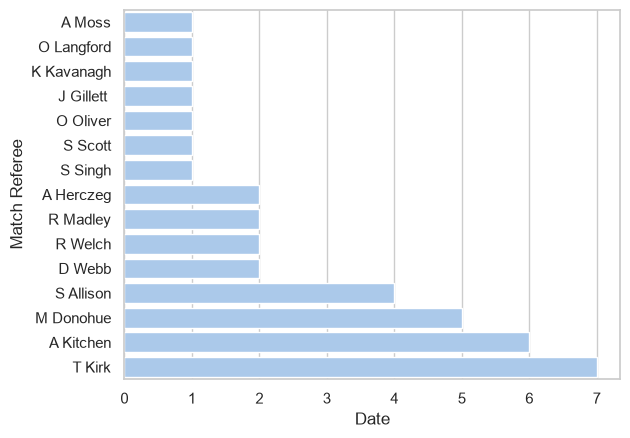

In [ ]:
# now take the same approach as home and away teams with refs
# agg the data
refs = (df.groupby('Match Referee')['Date']
            .count()
            .reset_index()
            .sort_values(ascending=True,by='Date')
)

ref_Count = df['Match Referee'].nunique()

print(f'There are {ref_Count} different Referees in the dataset')
sns.barplot(data=refs.head(15),x='Date',y='Match Referee');

## Data Type

In [ ]:
# set the match date a date data type

df['Date'].str.rfind('/')

# there were some errors in the date where the year was showing 06 instead of 2006.
# the below corrects this by finding the year with only 2 string values, then changing them to create the
# proper format.
df['Date'] = pd.to_datetime(
    df['Date'].apply(
    lambda x: x[:x.rfind('/')+1] + "20" + x[x.rfind('/')+1:]
    if len(x[x.rfind('/')+1:]) == 2 else x
))

In [ ]:
# add in time series features
df['DayofWeek'] = df['Date'].dt.day_name()
df['Month'] = df['Date'].dt.month_name()
df['Year'] = df['Date'].dt.year

# add in season of the year
def season_of_yr(x):
  if x in ['December','January','February']:
    return 'Winter'
  elif x in ['March','April','May']:
    return 'Spring'
  elif x in ['June','July','August']:
    return 'Summer'
  else:
    return 'Autumn'

# create feature
df['SeasonOfYear'] = df['Month'].apply(season_of_yr)

In [ ]:
df.head(10)

,Date,Time,HomeTeam,AwayTeam,FT_HomeGoals,FT_AwayGoals,FT_Result,HT_HomeGoals,HT_AwayGoals,HT_Result,...,AvgC>2.5,AvgC<2.5,AHCh,AvgCAHH,AvgCAHA,Season,DayofWeek,Month,Year,SeasonOfYear
0,2026-08-21,20:00,Arsenal,Coventry,3,0,H,2,0,H,...,1.55,2.37,-2.00,2.02,1.74,2627,Friday,August,2026,Summer
1,2026-08-22,12:30,Hull,Man United,2,0,H,2,0,H,...,1.55,2.38,1.50,1.82,1.92,2627,Saturday,August,2026,Summer
2,2026-08-22,15:00,Everton,Crystal Palace,2,0,H,1,0,H,...,1.93,1.83,-0.25,1.96,1.79,2627,Saturday,August,2026,Summer
3,2026-08-22,15:00,Ipswich,Sunderland,2,1,H,1,1,D,...,2.14,1.67,0.00,1.99,1.77,2627,Saturday,August,2026,Summer
4,2026-08-22,15:00,Nott'm Forest,Leeds,0,1,A,0,0,D,...,2.12,1.69,-0.25,2.07,1.70,2627,Saturday,August,2026,Summer
5,2026-08-22,17:30,Brentford,Tottenham,3,0,H,2,0,H,...,1.65,2.18,-0.50,1.95,1.79,2627,Saturday,August,2026,Summer
6,2026-08-23,14:00,Brighton,Aston Villa,4,0,H,4,0,H,...,1.93,1.82,-0.25,1.76,1.98,2627,Sunday,August,2026,Summer
7,2026-08-23,14:00,Man City,Bournemouth,2,1,H,0,1,A,...,1.52,2.45,-1.25,1.90,1.84,2627,Sunday,August,2026,Summer
8,2026-08-23,16:30,Newcastle,Liverpool,2,2,D,1,0,H,...,1.49,2.58,0.50,1.90,1.84,2627,Sunday,August,2026,Summer
9,2026-08-24,20:00,Fulham,Chelsea,2,3,A,1,2,A,...,1.84,1.91,0.50,1.79,1.95,2627,Monday,August,2026,Summer


In [ ]:
# save data for eda notebook
df.to_csv('data/clean_data.csv',index=False)